# Example walkthrough (synthetic data)

This notebook demonstrates the pipeline end to end **without real participant data** --
it generates a small synthetic dataset matching the real schema's shape (binary target,
~5-10% positive class, a handful of binary/continuous feature columns grouped into
`other_features` / `adolescent_features` / `adult_features`), then runs:

1. Train-only preprocessing (`fit_transform_ml_data`)
2. One outer-fold split
3. Random Forest fit with the ODD recipe (ADASYN resampling + Focal loss)
4. Metric computation on the held-out fold
5. Permutation importance on that same held-out fold

**None of the data or results below are real.** They exist only to prove the code runs.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT / "src"))

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

from recipe import get_recipe, get_cv_config
from stage3_loss_comparison import fit_rf_with_loss, resample_xy
from utils.models import compute_metrics, get_positive_scores, youden_threshold
from utils.preprocess import fit_transform_ml_data

print("Imports OK")

Imports OK


## 1. Generate a synthetic dataset (NOT real data)

In [2]:
rng = np.random.default_rng(42)
n = 300

# Synthetic metadata, matching the real schema's group structure (see data/README.md).
meta = {
    "other_features": ["region_code"],
    "adolescent_features": ["cyberbullying_victim", "screen_time_level", "smartphone_use_z", "academic_decline"],
    "adult_features": ["parent_anxiety_high", "parent_depression_high", "maternal_education"],
    "feature_types": {
        "region_code": "nominal",
        "cyberbullying_victim": "binary",
        "screen_time_level": "ordinal",
        "smartphone_use_z": "continuous",
        "academic_decline": "binary",
        "parent_anxiety_high": "binary",
        "parent_depression_high": "binary",
        "maternal_education": "ordinal",
    },
    "feature_groups": {
        "binary": ["cyberbullying_victim", "academic_decline", "parent_anxiety_high", "parent_depression_high"],
        "ordinal": ["screen_time_level", "maternal_education"],
        "nominal": ["region_code"],
        "continuous": ["smartphone_use_z"],
    },
}

target_col = "SYNTH_TARGET"
df = pd.DataFrame({
    "region_code": rng.integers(1, 4, n),
    "cyberbullying_victim": rng.binomial(1, 0.15, n),
    "screen_time_level": rng.integers(1, 6, n),
    "smartphone_use_z": rng.normal(0, 1, n),
    "academic_decline": rng.binomial(1, 0.2, n),
    "parent_anxiety_high": rng.binomial(1, 0.1, n),
    "parent_depression_high": rng.binomial(1, 0.08, n),
    "maternal_education": rng.integers(1, 5, n),
})

# A realistic ~7% positive class, weakly driven by a couple of the synthetic features
# (just enough signal for the pipeline to find something, not a claim about real effects).
logit = (-2.6 + 1.1 * df["cyberbullying_victim"] + 0.5 * df["smartphone_use_z"]
         + 0.8 * df["academic_decline"] + rng.normal(0, 0.5, n))
prob = 1 / (1 + np.exp(-logit))
df[target_col] = rng.binomial(1, prob)

print(df[target_col].value_counts(normalize=True))
df.head()

SYNTH_TARGET
0    0.9
1    0.1
Name: proportion, dtype: float64


,region_code,cyberbullying_victim,screen_time_level,smartphone_use_z,academic_decline,parent_anxiety_high,parent_depression_high,maternal_education,SYNTH_TARGET
0,1,0,1,1.247950,0,0,0,2,0
1,3,1,1,-0.252517,0,0,0,1,0
2,2,0,2,0.363454,1,0,0,4,0
3,2,0,5,-2.409922,1,0,0,1,0
4,2,0,3,-1.156348,1,0,0,2,0


## 2. One outer-fold split, train-only preprocessing

In [3]:
cv = get_cv_config()
cols = [c for g in ("other_features", "adolescent_features", "adult_features") for c in meta[g]]
X, y = df[cols], df[target_col]

skf = StratifiedKFold(n_splits=cv["outer_folds"], shuffle=True, random_state=cv["outer_seed"])
tr_idx, te_idx = next(iter(skf.split(X, y)))
X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
y_tr, y_te = y.iloc[tr_idx], y.iloc[te_idx]

# fit_transform_ml_data fits the preprocessor on X_tr ONLY, transforms X_te -- no leakage.
X_tr_ml, X_te_ml, _ = fit_transform_ml_data(X_tr, X_te, meta, target_col)
print("Train:", X_tr_ml.shape, "Test:", X_te_ml.shape)

Train: (150, 10) Test: (150, 10)


## 3. Fit the ODD recipe (ADASYN + Focal) on this synthetic fold

In [4]:
recipe = get_recipe("ODD")
print(recipe)

X_res, y_res = resample_xy(X_tr_ml, y_tr, recipe["sampler"], seed=cv["outer_seed"])
clf = fit_rf_with_loss(X_res, y_res, recipe["loss"], seed=cv["outer_seed"], focal_gamma=recipe["focal_gamma"])

scores_te = get_positive_scores(clf, X_te_ml)
th = youden_threshold(y_tr, get_positive_scores(clf, X_tr_ml))
pred_te = (scores_te >= th).astype(int)

metrics = compute_metrics(y_te, pred_te, scores_te)
metrics["AUC"] = roc_auc_score(y_te, scores_te)
metrics

{'target_column': 'ODD_CP', 'model': 'RandomForest', 'n_estimators': 500, 'sampler': 'ADASYN', 'loss': 'Focal', 'focal_gamma': 2.0, 'hyperparameters': {'criterion': 'gini', 'min_samples_leaf': 1, 'max_depth': None, 'max_features': 'sqrt'}, 'final_outer_test_auc_combined': 0.871}


{'Accuracy': 0.8933333333333333,
 'Sensitivity': np.float64(0.0),
 'Specificity': np.float64(0.9925925925925926),
 'Precision': 0.0,
 'Recall': 0.0,
 'F1-score': 0.0,
 'AUC Score': np.float64(0.6241975308641976),
 'AUC': np.float64(0.6241975308641976)}

## 4. Permutation importance on the held-out fold

On this tiny synthetic sample the bars are noisy -- the point is that the code runs and the held-out fold is never touched before this line, not that the ranking is meaningful.

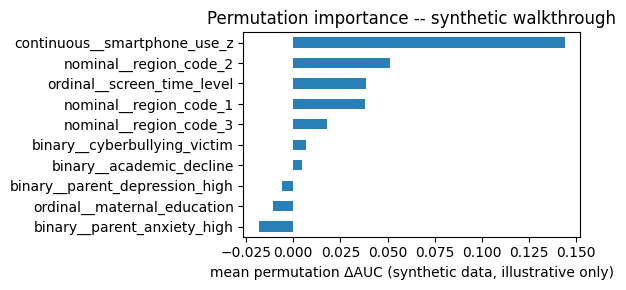

In [5]:
pi = permutation_importance(clf, X_te_ml, y_te.to_numpy(), scoring="roc_auc", n_repeats=8,
                             random_state=cv["outer_seed"], n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_te_ml.columns).sort_values(ascending=False)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3))
imp.iloc[::-1].plot.barh(ax=ax, color="#2980b9")
ax.set_xlabel("mean permutation ΔAUC (synthetic data, illustrative only)")
ax.set_title("Permutation importance -- synthetic walkthrough")
plt.tight_layout()
plt.show()

## Next steps

To run this on the real cohort: obtain data access per [`data/README.md`](../data/README.md), place the files as documented, then use `src/run_pipeline.py --target ODD` / `--target DICCD` instead of this synthetic walkthrough.